# 🎰 termslot.py — Demo av Vegas en maskin

Den här notebooken är fristående:

1. installerar beroenden,
2. skriver `termslot_sv.py` bredvid notebooken,
3. kör det interaktiva widgetgränssnittet,
4. spelar ett spel via spellogikens API och **visualiserar** resultaten (saldokurva, fördelning av utbetalningar, RTP-konvergens och många spelsessioner).

In [1]:
import importlib.util

# Installera bara det som saknas (ingen åtgärd om allt redan finns).
missing = [p for p in ("ipywidgets", "matplotlib", "numpy") if importlib.util.find_spec(p) is None]
if missing:
    get_ipython().run_line_magic("pip", "install -q " + " ".join(missing))
else:
    print("Alla beroenden är redan installerade.")

Alla beroenden är redan installerade.


## 1. Modulen (`termslot.py`)

In [2]:
%%writefile termslot.py
"""En enkel spelautomat för JupyterLab och Jupyter Notebook.

Installera widget-beroendet vid behov::

    %pip install ipywidgets

Kör sedan i en notebook-cell::

    from termslot_sv import show_slot_machine
    game = show_slot_machine()

Spellogiken kan också användas utan notebook-gränssnittet via
``SlotMachine`` och dess metoder ``spin()`` / ``play()``.
"""

from __future__ import annotations

import random
from dataclasses import dataclass
from typing import Iterator

import ipywidgets as widgets
from IPython.display import display

JACKPOT_THRESHOLD = 1000

# --- Utbetalningstabell ------------------------------------------------------
# Utbetalningarna är multiplar av insatsen, så återbetalningsandelen (RTP) är
# densamma för alla insatsstorlekar. Varje snurr drar ett utfall likformigt ur
# denna pool:
#   * små vinster:   randint(1 x insats, m x insats) för varje m i SMALL_WIN_MULTIPLES
#   * ingen vinst:   ZERO_OUTCOMES poster som betalar 0
#   * breda vinster: randint(0, m x insats) för varje m i WIDE_WIN_MULTIPLES
# Med dessa värden blir RTP 58,5 / 61 = 95,9 %.
SMALL_WIN_MULTIPLES = (2, 2, 4, 6, 8, 9)
ZERO_OUTCOMES = 53
WIDE_WIN_MULTIPLES = (30, 50)


def theoretical_rtp() -> float:
    """Exakt återbetalningsandel (RTP) som bråkdel (0,959 betyder 95,9 %).

    Medelvärdet av randint(a, b) är (a + b) / 2, så den förväntade
    utbetalningen per snurr, uttryckt i insatser, är en summa av enkla
    medelvärden delad med poolens storlek.
    """
    expected = sum((1 + m) / 2 for m in SMALL_WIN_MULTIPLES)
    expected += sum(m / 2 for m in WIDE_WIN_MULTIPLES)
    pool = len(SMALL_WIN_MULTIPLES) + ZERO_OUTCOMES + len(WIDE_WIN_MULTIPLES)
    return expected / pool



@dataclass
class SpinResult:
    """Utfallet av en snurr."""

    status: str  # "insufficient", "jackpot", "game_over" eller "ok"
    win_amount: int = 0
    deposit: int = 0
    message: str = ""


class SlotMachine:
    """Spellogik, oberoende av notebook-gränssnittet."""

    def __init__(self, deposit: int = 100, bet: int = 5, attempts: int = 1):
        if deposit < 0:
            raise ValueError("Insättningen kan inte vara negativ.")
        if bet <= 0:
            raise ValueError("Insatsen måste vara större än noll.")
        if attempts < 0:
            raise ValueError("Antalet försök kan inte vara negativt.")

        self.deposit = deposit
        self.bet = bet
        self.attempts = attempts
        self.game_over = False

    @property
    def balance(self) -> str:
        """Returnera aktuellt saldo i spelets visningsformat."""
        return f"{self.deposit}:-"

    def _spin_wheel(self) -> int:
        """Välj en utbetalning ur poolen som beskrivs i utbetalningstabellen."""
        bet = self.bet
        n_small = len(SMALL_WIN_MULTIPLES)
        pick = random.randrange(n_small + ZERO_OUTCOMES + len(WIDE_WIN_MULTIPLES))

        if pick < n_small:
            return random.randint(bet, SMALL_WIN_MULTIPLES[pick] * bet)
        pick -= n_small
        if pick < ZERO_OUTCOMES:
            return 0
        return random.randint(0, WIDE_WIN_MULTIPLES[pick - ZERO_OUTCOMES] * bet)

    def spin(self) -> SpinResult:
        """Spela en runda och returnera resultatet."""
        if self.game_over:
            return SpinResult(
                status="game_over",
                deposit=self.deposit,
                message="Spelet är slut. Starta ett nytt spel för att spela igen.",
            )

        if self.deposit < self.bet:
            self.game_over = True
            return SpinResult(
                status="insufficient",
                deposit=self.deposit,
                message="Inte tillräckligt med krediter för ännu en insats.",
            )

        self.deposit -= self.bet
        win_amount = self._spin_wheel()
        self.deposit += win_amount

        if self.deposit >= JACKPOT_THRESHOLD:
            self.game_over = True
            return SpinResult(
                status="jackpot",
                win_amount=win_amount,
                deposit=self.deposit,
                message=(
                    f"JACKPOT! Utbetalning: {win_amount}:-. "
                    f"Slutsaldo: {self.deposit}:-."
                ),
            )

        # Avsluta spelet om det återstående saldot inte räcker till en ny insats.
        if self.deposit < self.bet:
            self.game_over = True
            return SpinResult(
                status="game_over",
                win_amount=win_amount,
                deposit=self.deposit,
                message=(
                    f"Utbetalning: {win_amount}:-. "
                    "Inte tillräckligt med krediter för ännu en insats."
                ),
            )

        return SpinResult(
            status="ok",
            win_amount=win_amount,
            deposit=self.deposit,
            message=f"Utbetalning: {win_amount}:-.",
        )

    def play(self) -> Iterator[str]:
        """Ge meddelanden för upp till ``attempts`` snurr (batchanvändning)."""
        for _ in range(self.attempts):
            result = self.spin()
            yield result.message
            if result.status != "ok":
                break


# Utbetalningen, som multipel av insatsen, avgör vilka symboler hjulen visar.
_TIERS = (
    (0, ("🍋", "🍇", "🔔")),
    (2, ("🍒", "🍒", "🍒")),
    (10, ("🔔", "🔔", "🔔")),
    (30, ("⭐", "⭐", "⭐")),
    (float("inf"), ("💎", "💎", "💎")),
)


def _symbols_for(win_amount: int, bet: int = 5) -> tuple[str, str, str]:
    """Returnera en symbolkombination som passar en utbetalning.

    ``bet`` är den insats utbetalningen hör till (standard: spelets
    standardinsats), eftersom symbolnivåerna är multiplar av insatsen.
    """
    multiple = win_amount / bet
    for ceiling, symbols in _TIERS:
        if multiple <= ceiling:
            return symbols
    return _TIERS[-1][1]


class NotebookSlotMachine:
    """ipywidgets-gränssnitt för att spela spelet i en notebook."""

    def __init__(self, deposit: int = 100, bet: int = 5):
        self.machine = SlotMachine(deposit=deposit, bet=bet)

        self.deposit_input = widgets.IntText(
            value=deposit,
            description="Insättning:",
            style={"description_width": "initial"},
        )
        self.bet_input = widgets.IntText(
            value=bet,
            description="Insats:",
            style={"description_width": "initial"},
        )
        self.spin_button = widgets.Button(
            description="Snurra", button_style="success", icon="play"
        )
        self.reset_button = widgets.Button(
            description="Nytt spel", button_style="warning", icon="refresh"
        )
        self.reels = widgets.HTML()
        self.status = widgets.HTML()
        self.history = widgets.Output(
            layout=widgets.Layout(border="1px solid #ccc", padding="8px")
        )
        self.progress = widgets.IntProgress(
            value=min(deposit, JACKPOT_THRESHOLD),
            min=0,
            max=JACKPOT_THRESHOLD,
            description="Jackpot:",
            style={"description_width": "initial"},
        )

        self.spin_button.on_click(self._on_spin)
        self.reset_button.on_click(self._on_reset)

        self.widget = widgets.VBox(
            [
                widgets.HTML("<h2>🎰 Spelautomat</h2>"),
                widgets.HBox([self.deposit_input, self.bet_input]),
                widgets.HBox([self.spin_button, self.reset_button]),
                self.reels,
                self.status,
                self.progress,
                widgets.HTML("<b>Spelhistorik</b>"),
                self.history,
            ]
        )
        self._refresh()

    def _refresh(
        self,
        message: str = "Redo att spela.",
        symbols: tuple[str, str, str] = ("🍒", "🍋", "🔔"),
    ) -> None:
        self.reels.value = (
            '<div style="font-size:2em;text-align:center">'
            + "　".join(symbols)
            + "</div>"
        )
        self.status.value = (
            f"<b>Saldo:</b> {self.machine.balance} &nbsp; "
            f"<b>Insats:</b> {self.machine.bet}:-<br>{message}"
        )
        self.progress.value = min(max(self.machine.deposit, 0), JACKPOT_THRESHOLD)
        self.spin_button.disabled = self.machine.game_over

    def _on_spin(self, _button: widgets.Button) -> None:
        result = self.machine.spin()
        self._refresh(result.message, _symbols_for(result.win_amount, self.machine.bet))
        with self.history:
            print(result.message)

    def _on_reset(self, _button: widgets.Button) -> None:
        deposit = int(self.deposit_input.value)
        bet = int(self.bet_input.value)
        if deposit < 0 or bet <= 0:
            self.status.value = (
                "<span style='color:#b00020'>"
                "Insättningen måste vara noll eller mer, och insatsen måste vara "
                "större än noll."
                "</span>"
            )
            return

        self.machine = SlotMachine(deposit=deposit, bet=bet)
        self.history.clear_output()
        self._refresh("Nytt spel startat.")


def show_slot_machine(deposit: int = 100, bet: int = 5) -> NotebookSlotMachine:
    """Visa spelet i JupyterLab/Notebook och returnera dess styrobjekt."""
    game = NotebookSlotMachine(deposit=deposit, bet=bet)
    display(game.widget)
    return game


if __name__ == "__main__":
    print("Den här modulen är avsedd för JupyterLab/Notebook.")
    print("Kör i en notebook-cell: from termslot_sv import show_slot_machine; show_slot_machine()")

Overwriting termslot_sv.py


## 2. Interaktivt gränssnitt
Tryck på **Snurra** för att spela. Nedan utlöses fem snurr via kod så att resultatet syns även i en statisk vy.

In [3]:
import random
random.seed(7)

from termslot_sv import show_slot_machine

game = show_slot_machine(deposit=100, bet=5)
for _ in range(5):
    game.spin_button.click()

## 3. Spela en session via spellogikens API

In [4]:
import random
import matplotlib.pyplot as plt
from termslot_sv import SlotMachine, JACKPOT_THRESHOLD, theoretical_rtp

random.seed(42)

def play_session(deposit=100, bet=5, max_spins=5000):
    m = SlotMachine(deposit=deposit, bet=bet)
    balances, wins = [deposit], []
    last = None
    for _ in range(max_spins):
        r = m.spin()
        last = r
        if r.status == "insufficient":
            break
        balances.append(r.deposit)
        wins.append(r.win_amount)
        if r.status != "ok":
            break
    return balances, wins, last

balances, wins, last = play_session()
print(f"Antal snurr    : {len(wins)}")
print(f"Slutsaldo      : {balances[-1]}:-")
print(f"Sista status   : {last.status} -> {last.message}")

Antal snurr    : 38
Slutsaldo      : 0:-
Sista status   : game_over -> Utbetalning: 0:-. Inte tillräckligt med krediter för ännu en insats.


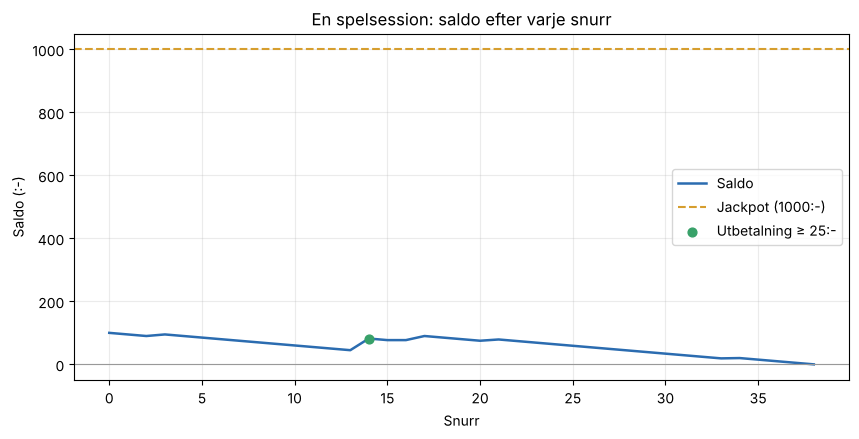

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = range(len(balances))
ax.plot(x, balances, color="#2b6cb0", lw=1.8, label="Saldo")
ax.axhline(JACKPOT_THRESHOLD, color="#d69e2e", ls="--", label=f"Jackpot ({JACKPOT_THRESHOLD}:-)")
ax.axhline(0, color="#999", lw=0.8)
# markera snurr som gav minst 25:- i utbetalning
big = [i + 1 for i, w in enumerate(wins) if w >= 25]
ax.scatter(big, [balances[i] for i in big], color="#38a169", zorder=3, s=40, label="Utbetalning ≥ 25:-")
ax.set_title("En spelsession: saldo efter varje snurr")
ax.set_xlabel("Snurr"); ax.set_ylabel("Saldo (:-)")
ax.legend(); ax.grid(alpha=0.25)
plt.show()

## 4. Hjulgrafik för sista snurren
(Ritad med former, så att den fungerar utan emoji-typsnitt.)

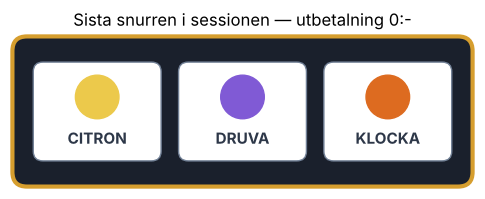

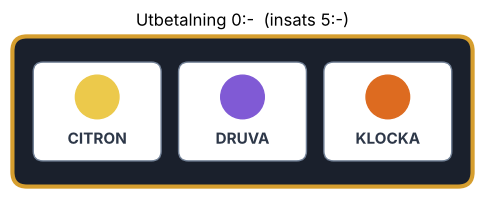

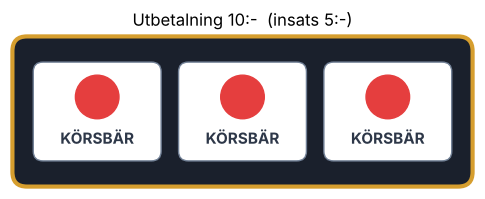

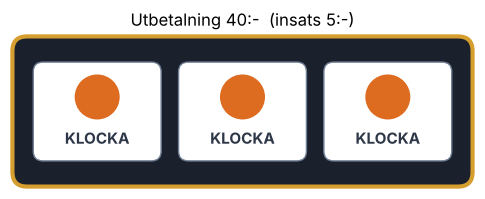

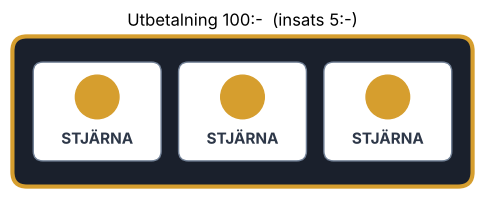

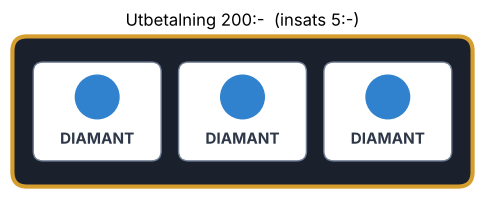

In [6]:
from matplotlib.patches import FancyBboxPatch
from termslot_sv import _symbols_for

NAMES  = {"🍋": ("CITRON", "#ecc94b"), "🍇": ("DRUVA", "#805ad5"), "🔔": ("KLOCKA", "#dd6b20"),
          "🍒": ("KÖRSBÄR", "#e53e3e"), "⭐": ("STJÄRNA", "#d69e2e"), "💎": ("DIAMANT", "#3182ce")}

def draw_reels(win_amount, bet=5, title=""):
    symbols = _symbols_for(win_amount, bet)
    fig, ax = plt.subplots(figsize=(6, 2.6))
    ax.set_xlim(0, 9.6); ax.set_ylim(0, 3.2); ax.set_aspect("equal"); ax.axis("off")
    ax.add_patch(FancyBboxPatch((0.1, 0.1), 9.4, 3.0, boxstyle="round,pad=0.05,rounding_size=0.3",
                                fc="#1a202c", ec="#d69e2e", lw=3))
    for i, s in enumerate(symbols):
        name, color = NAMES[s]
        ax.add_patch(FancyBboxPatch((0.5 + i * 3.0, 0.6), 2.6, 2.0,
                                    boxstyle="round,pad=0.02,rounding_size=0.2", fc="white", ec="#718096"))
        ax.add_patch(plt.Circle((1.8 + i * 3.0, 1.9), 0.45, color=color))
        ax.text(1.8 + i * 3.0, 1.05, name, ha="center", va="center", fontsize=11, weight="bold", color="#2d3748")
    ax.set_title(title or f"Utbetalning {win_amount}:-  (insats {bet}:-)", fontsize=12)
    plt.show()

draw_reels(wins[-1], 5, f"Sista snurren i sessionen — utbetalning {wins[-1]}:-")
# Visa ett exempel för varje vinstnivå
for w in (0, 10, 40, 100, 200):
    draw_reels(w, 5)

## 5. Fördelning av utbetalningar (100 000 snurr)

Uppmätt RTP (återbetalningsandel): 96.557%
Teoretisk RTP                    : 95.902%
Träffprocent (vinst > 0)         : 13.17%
Största utbetalning              : 250:-


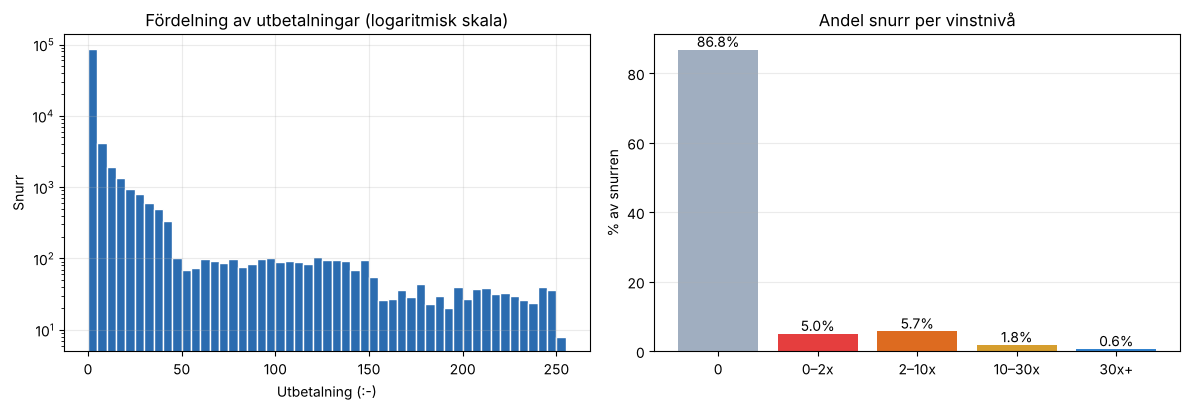

In [7]:
import numpy as np
random.seed(1)

N, BET = 100_000, 5
m = SlotMachine(deposit=10**9, bet=BET)
payouts = np.array([m._spin_wheel() for _ in range(N)])

print(f"Uppmätt RTP (återbetalningsandel): {payouts.mean() / BET:.3%}")
print(f"Teoretisk RTP                    : {theoretical_rtp():.3%}")
print(f"Träffprocent (vinst > 0)         : {(payouts > 0).mean():.2%}")
print(f"Största utbetalning              : {payouts.max()}:-")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].hist(payouts, bins=np.arange(0, payouts.max() + 6, 5), color="#2b6cb0", edgecolor="white")
axes[0].set_yscale("log")
axes[0].set_title("Fördelning av utbetalningar (logaritmisk skala)")
axes[0].set_xlabel("Utbetalning (:-)"); axes[0].set_ylabel("Snurr"); axes[0].grid(alpha=0.25)

mult = payouts / BET
bands = [("0", mult == 0), ("0–2x", (mult > 0) & (mult <= 2)), ("2–10x", (mult > 2) & (mult <= 10)),
         ("10–30x", (mult > 10) & (mult <= 30)), ("30x+", mult > 30)]
share = [b.mean() * 100 for _, b in bands]
bars = axes[1].bar([n for n, _ in bands], share,
                   color=["#a0aec0", "#e53e3e", "#dd6b20", "#d69e2e", "#3182ce"])
axes[1].set_title("Andel snurr per vinstnivå"); axes[1].set_ylabel("% av snurren")
for b, s in zip(bars, share):
    axes[1].text(b.get_x() + b.get_width() / 2, s + 0.8, f"{s:.1f}%", ha="center")
axes[1].grid(alpha=0.25, axis="y")
plt.tight_layout(); plt.show()

## 6. RTP-konvergens (återbetalningsandel)

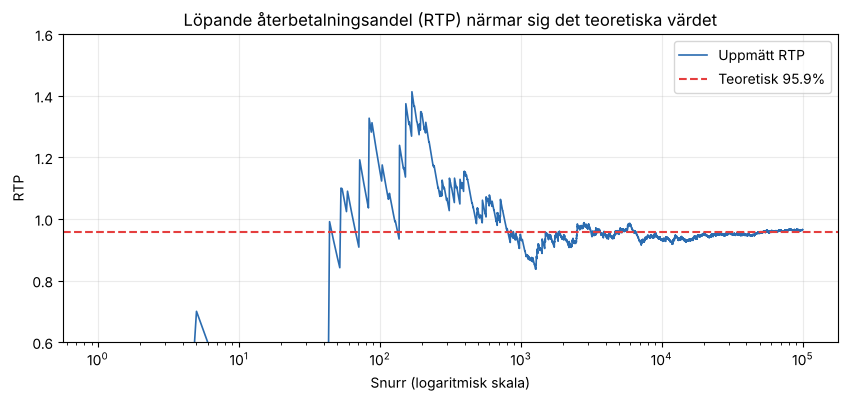

In [8]:
running = np.cumsum(payouts) / (BET * np.arange(1, N + 1))
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(running, color="#2b6cb0", lw=1.2, label="Uppmätt RTP")
ax.axhline(theoretical_rtp(), color="#e53e3e", ls="--", label=f"Teoretisk {theoretical_rtp():.1%}")
ax.set_xscale("log"); ax.set_ylim(0.6, 1.6)
ax.set_title("Löpande återbetalningsandel (RTP) närmar sig det teoretiska värdet")
ax.set_xlabel("Snurr (logaritmisk skala)"); ax.set_ylabel("RTP"); ax.legend(); ax.grid(alpha=0.25)
plt.show()

## 7. Många sessioner: hur ofta träffar spelare jackpot?
Varje spelare börjar med 100:- och spelar med 5:- i insats tills pengarna är slut eller 1000:- nås.

Jackpot-träffar: 112 / 2000 (5.60%)
Mediansession  : 44 snurr


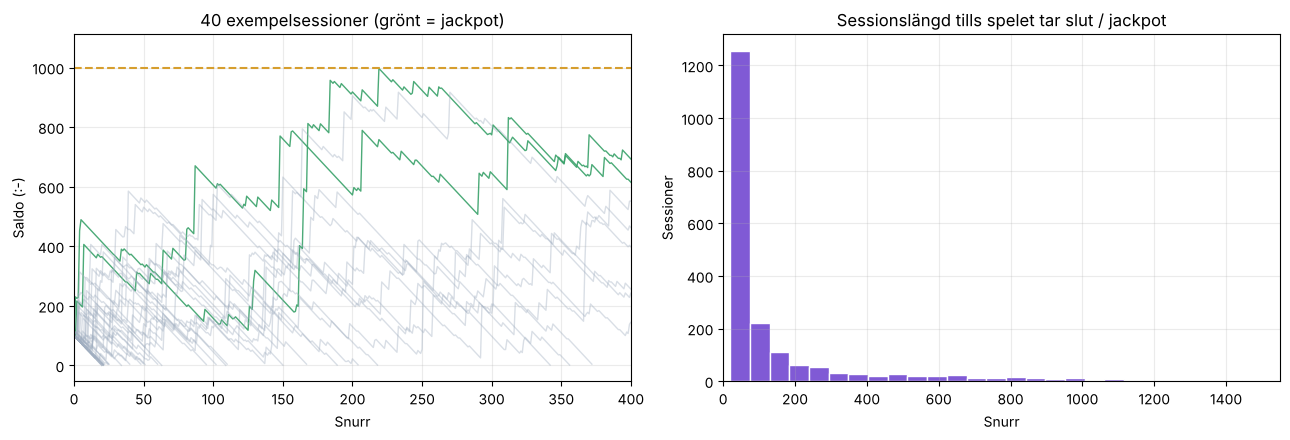

In [9]:
random.seed(2026)
SESSIONS = 2000
results = [play_session(max_spins=20000) for _ in range(SESSIONS)]
jackpots = sum(1 for b, _, last in results if last.status == "jackpot")
lengths  = [len(w) for _, w, _ in results]
print(f"Jackpot-träffar: {jackpots} / {SESSIONS} ({jackpots / SESSIONS:.2%})")
print(f"Mediansession  : {int(np.median(lengths))} snurr")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for b, _, last in results[:40]:
    axes[0].plot(b, color="#38a169" if last.status == "jackpot" else "#a0aec0",
                 alpha=0.9 if last.status == "jackpot" else 0.4, lw=1)
axes[0].axhline(JACKPOT_THRESHOLD, color="#d69e2e", ls="--")
axes[0].set_title("40 exempelsessioner (grönt = jackpot)")
axes[0].set_xlabel("Snurr"); axes[0].set_ylabel("Saldo (:-)"); axes[0].set_xlim(0, 400)
axes[0].grid(alpha=0.25)

axes[1].hist(lengths, bins=60, color="#805ad5", edgecolor="white")
axes[1].set_xlim(0, np.percentile(lengths, 99))
axes[1].set_title("Sessionslängd tills spelet tar slut / jackpot")
axes[1].set_xlabel("Snurr"); axes[1].set_ylabel("Sessioner"); axes[1].grid(alpha=0.25)
plt.tight_layout(); plt.show()